In [58]:
import pandas as pd
import numpy as np

import scipy.stats as stats

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import ColumnTransformer

In [59]:
df = pd.read_csv('E:\\Data Science\\Machine Learning\\data\\train.csv', usecols=['Age','Fare','Survived'])

In [60]:
df.head(10)

,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500
5,0,NaN,8.4583
6,0,54.0,51.8625
7,0,2.0,21.0750
8,1,27.0,11.1333
9,1,14.0,30.0708


In [61]:
df.isnull().sum()

Survived      0
Age         177
Fare          0
dtype: int64

In [62]:
df["Age"] = df['Age'].fillna(df['Age'].mean().round(2))

In [63]:
X = df.iloc[:,1:3]
y = df.iloc[:,0]

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)

C:\Users\Anwoy\AppData\Local\Temp\ipykernel_3708\1374816729.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(X_train['Age'])


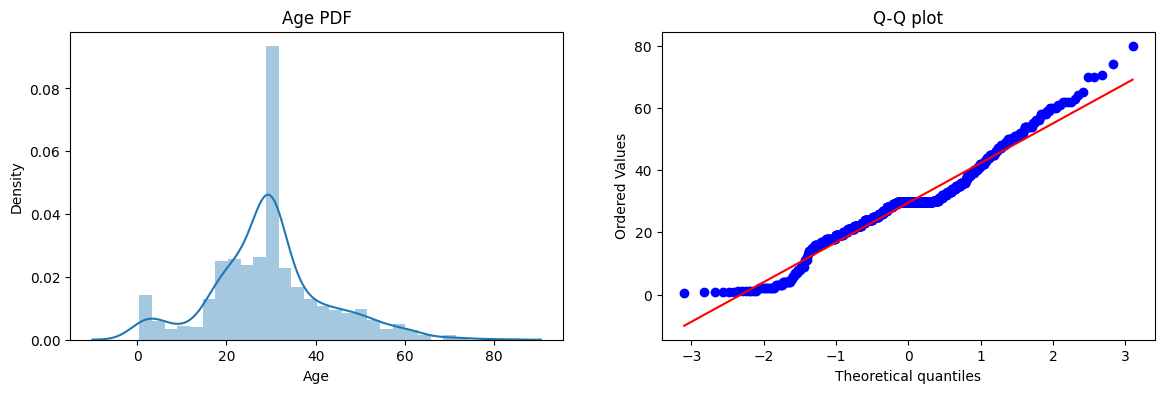

In [64]:
plt.figure(figsize= (14,4))
plt.subplot(121)
sns.distplot(X_train['Age'])
plt.title("Age PDF")

plt.subplot(122)
stats.probplot(X_train['Age'], dist = 'norm', plot = plt)
plt.title("Q-Q plot")
plt.show()

C:\Users\Anwoy\AppData\Local\Temp\ipykernel_3708\2981780686.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(X_train['Fare'])


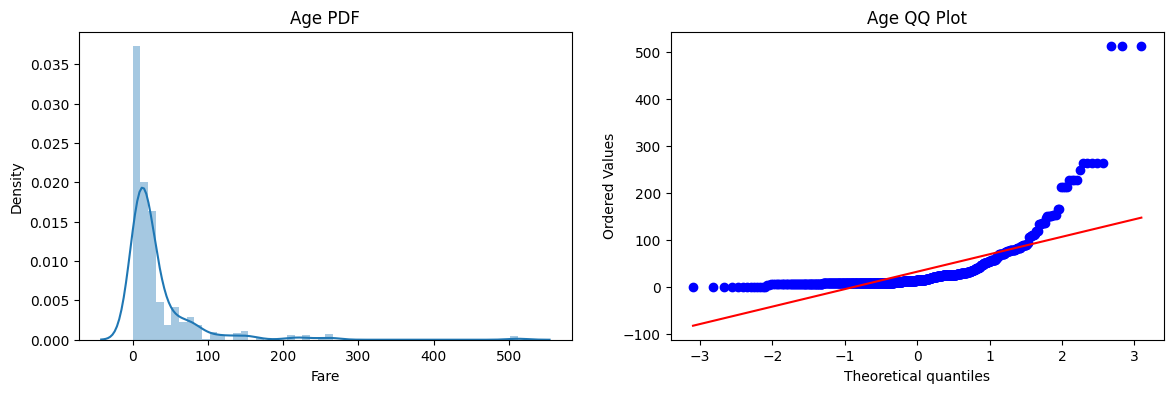

In [65]:
plt.figure(figsize=(14,4))
plt.subplot(121)
sns.distplot(X_train['Fare'])
plt.title('Age PDF')

plt.subplot(122)
stats.probplot(X_train['Fare'], dist="norm", plot=plt)
plt.title('Age QQ Plot')

plt.show()

### Accuracy without any transformation:

In [66]:
clf = LogisticRegression()
clf2 = DecisionTreeClassifier()
clf.fit(X_train,y_train)
clf2.fit(X_train,y_train)
    
y_pred = clf.predict(X_test)
y_pred1 = clf2.predict(X_test)
    
print("Accuracy LR",accuracy_score(y_test,y_pred))
print("Accuracy DT",accuracy_score(y_test,y_pred1))

Accuracy LR 0.6480446927374302
Accuracy DT 0.6759776536312849


In [67]:
## Creating log transformer
trf = FunctionTransformer(func = np.log1p) #if the variable to be transformed contains 0 log will give an error. Hence, we use log1p, which adds
                                           # 1 to each observation applying log.

In [68]:
X_train_transformed = trf.fit_transform(X_train)
X_test_transformed = trf.fit_transform(X_test)

In [69]:
clf.fit(X_train_transformed, y_train)
clf2.fit(X_train_transformed, y_train)

print("Accuracy LR",accuracy_score(y_test,clf.predict(X_test_transformed)))
print("Accuracy DT",accuracy_score(y_test,clf2.predict(X_test_transformed)))

Accuracy LR 0.6815642458100558
Accuracy DT 0.6703910614525139


##### Validating the change in result using cross-validation

In [70]:
X_transformed = trf.fit_transform(X)

clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

print("LR",np.mean(cross_val_score(clf,X_transformed,y,scoring='accuracy',cv=10)))
print("DT",np.mean(cross_val_score(clf2,X_transformed,y,scoring='accuracy',cv=10)))

LR 0.678027465667915
DT 0.6566167290886391


In [71]:
X_transformed

,Age,Fare
0,3.135494,2.110213
1,3.663562,4.280593
2,3.295837,2.188856
3,3.583519,3.990834
4,3.583519,2.202765
...,...,...
886,3.332205,2.639057
887,2.995732,3.433987
888,3.424263,3.196630
889,3.295837,3.433987


#### Compairing before and after log transformation:

Text(0.5, 1.0, 'Age after')

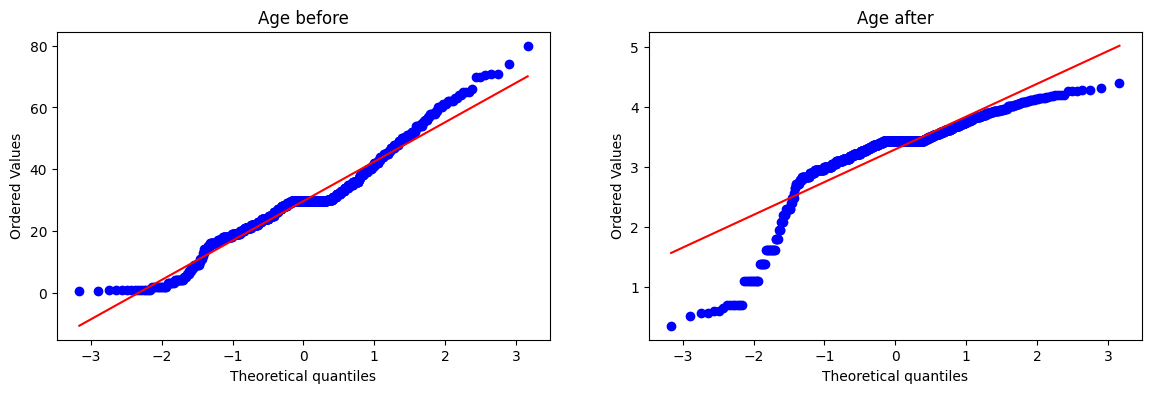

In [45]:
plt.figure(figsize= (14,4))

plt.subplot(121)
stats.probplot(X['Age'], dist='norm', plot = plt)
plt.title('Age before')

plt.subplot(122)
stats.probplot(X_transformed['Age'], dist = 'norm', plot = plt)
plt.title("Age after")

Text(0.5, 1.0, 'Fare after')

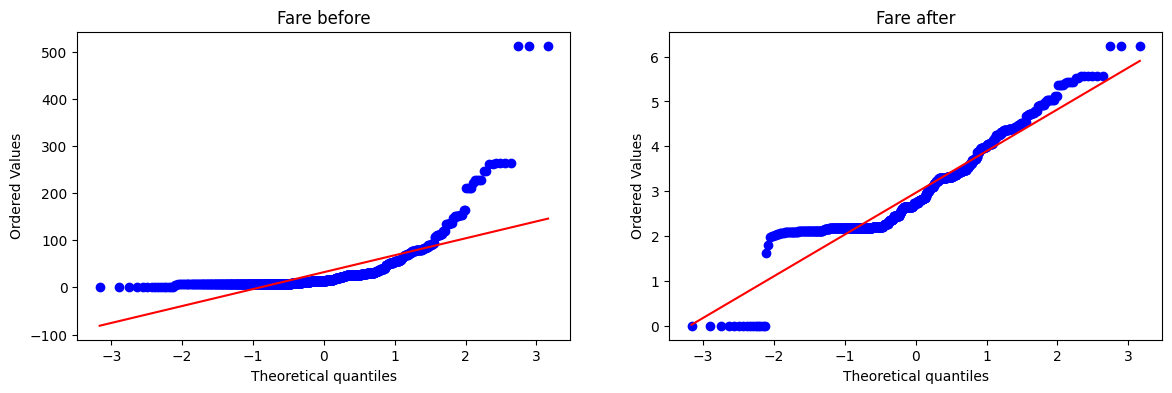

In [46]:
plt.figure(figsize= (14,4))

plt.subplot(121)
stats.probplot(X['Fare'], dist='norm', plot = plt)
plt.title('Fare before')

plt.subplot(122)
stats.probplot(X_transformed['Fare'], dist = 'norm', plot = plt)
plt.title("Fare after")

#### Age seems to be more disoriented after log transformation. let's apply transformation without it!

In [47]:
trf2 = ColumnTransformer([
    ('log', FunctionTransformer(func= np.log1p), ['Fare'])
], remainder= 'passthrough')

In [48]:
X_train_transformed2 = trf2.fit_transform(X_train)
X_test_transformed2 = trf2.fit_transform(X_test)

In [50]:
X_train_transformed2

array([[ 3.38439026, 45.5       ],
       [ 2.63905733, 23.        ],
       [ 2.18885633, 32.        ],
       ...,
       [ 2.71524426, 41.        ],
       [ 4.79579055, 14.        ],
       [ 4.36038795, 21.        ]])

In [51]:
clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

clf.fit(X_train_transformed2,y_train)
clf2.fit(X_train_transformed2,y_train)
    
y_pred = clf.predict(X_test_transformed2)
y_pred2 = clf2.predict(X_test_transformed2)
    
print("Accuracy LR",accuracy_score(y_test,y_pred))
print("Accuracy DT",accuracy_score(y_test,y_pred2))

Accuracy LR 0.6703910614525139
Accuracy DT 0.6759776536312849


In [52]:
X_transformed2 = trf2.fit_transform(X)

clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

print("LR",np.mean(cross_val_score(clf,X_transformed2,y,scoring='accuracy',cv=10)))
print("DT",np.mean(cross_val_score(clf2,X_transformed2,y,scoring='accuracy',cv=10)))

LR 0.6712609238451936
DT 0.6588514357053683


In [53]:
#### Creating a function to apply other transformations and plot the difference:

def apply_transform(transform):
    X = df.iloc[:,1:3]
    y = df.iloc[:,0]
    
    trf = ColumnTransformer([('func_trf',FunctionTransformer(transform),['Fare'])],remainder='passthrough')
    
    X_trans = trf.fit_transform(X)
    
    clf = LogisticRegression()
    
    print("Accuracy",np.mean(cross_val_score(clf,X_trans,y,scoring='accuracy',cv=10)))
    
    plt.figure(figsize=(14,4))

    plt.subplot(121)
    stats.probplot(X['Fare'], dist="norm", plot=plt)
    plt.title('Fare Before Transform')

    plt.subplot(122)
    stats.probplot(X_trans[:,0], dist="norm", plot=plt)
    plt.title('Fare After Transform')

    plt.show()
    

Accuracy 0.61729088639201


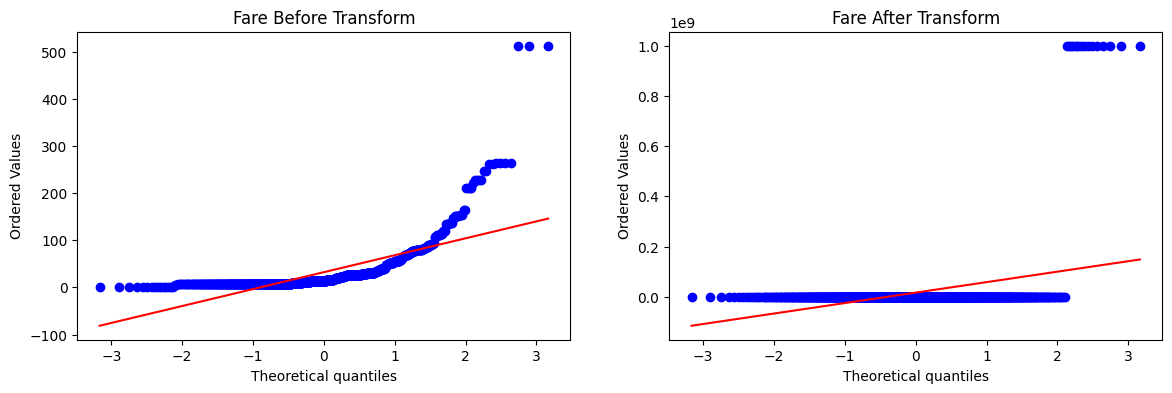

In [56]:
apply_transform(lambda x: 1/(x+0.000000001) )

Accuracy 0.6589013732833957


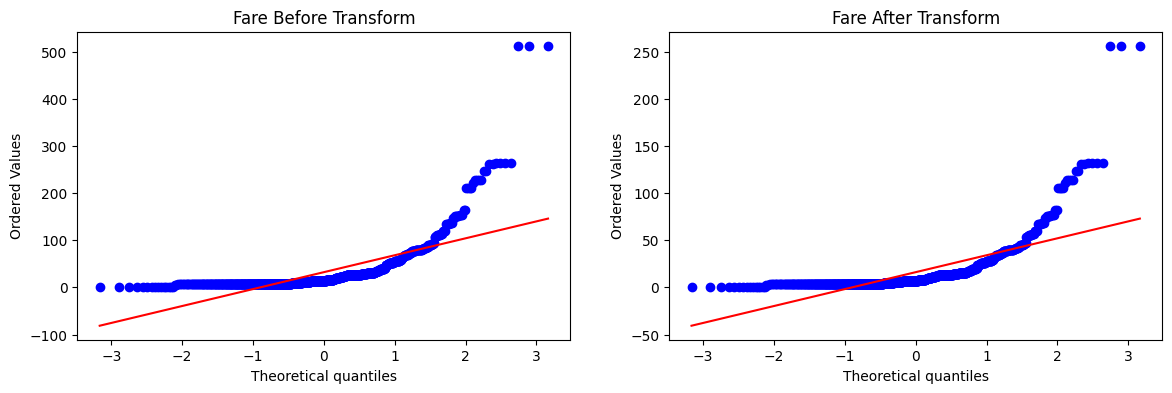

In [57]:
apply_transform(lambda x: x**1/2)